# Rolling Zipfian Narrative Windows from Pride and Prejudice

This notebook demonstrates the creation and analysis of rolling windows from Pride and Prejudice to observe linguistic dynamics, specifically focusing on function/content word ratios and type-token ratios across the narrative.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# Non-Colab packages
_pip('loguru==0.7.3')

# Colab packages
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'pandas==2.2.2', 'scikit-learn==1.6.1', 'matplotlib==3.10.0', 'nltk==3.9.1')

In [2]:
import json
import re
import http.client
import urllib.request
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np

# Figure style
COLOURS = {
    "method": "#0173B2",
    "baseline": "#949494",
    "other_1": "#DE8F05",
    "other_2": "#029E73",
    "other_3": "#CC78BC",
    "other_4": "#CA9161",
    "other_5": "#56B4E9",
}
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["CMU Serif", "Computer Modern Roman", "DejaVu Serif"],
    "mathtext.fontset": "cm",
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.grid.axis": "y",
    "grid.color": "#CCCCCC",
    "grid.alpha": 0.6,
    "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=list(COLOURS.values())),
    "image.cmap": "cividis",
    "legend.frameon": False,
    "figure.constrained_layout.use": True,
    "figure.dpi": 120,
})

Matplotlib is building the font cache; this may take a moment.


In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-624cdf-local-zipfian-curvature-as-narrative/main/round-1/dataset-1/demo/mini_demo_data.json"

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

data = load_data()

GitHub data unavailable, using local mini_demo_data.json: HTTP Error 404: Not Found


In [4]:
# Config
N_SAMPLES_TO_PROCESS = 3 # Smallest possible for demo

## Processing Data
Parsing the JSON-formatted data for visualization.

In [5]:
import pandas as pd

# Extract examples
examples = data['datasets'][0]['examples'][:N_SAMPLES_TO_PROCESS]
processed_data = []

for ex in examples:
    output = json.loads(ex['output'])
    processed_data.append({
        "window_index": ex['metadata_window_index'],
        "function_word_ratio": output['function_word_ratio'],
        "type_token_ratio": output['type_token_ratio']
    })

df = pd.DataFrame(processed_data)
print(df.head())

   window_index  function_word_ratio  type_token_ratio
0             0             0.576000          0.382667
1             1             0.578667          0.389333
2             2             0.574667          0.398667


## Visualization
Plotting function word ratio over window indices.

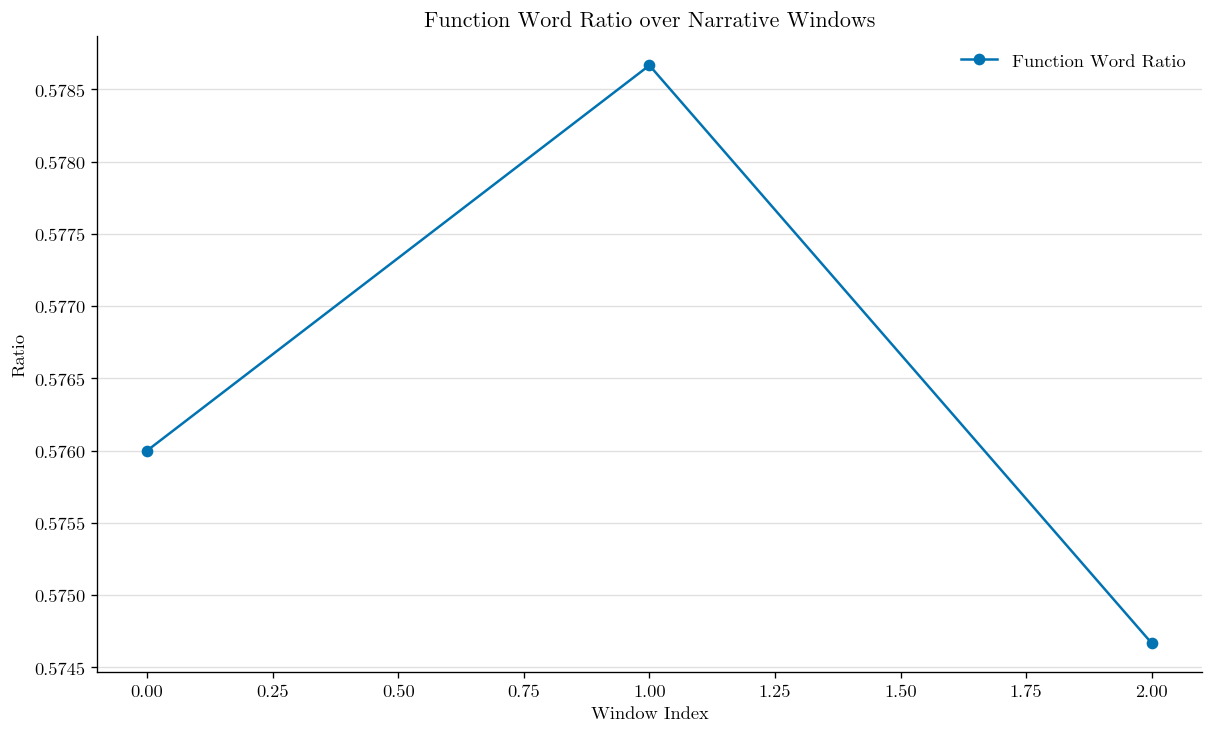

In [6]:
plt.figure(figsize=(10, 6))
plt.plot(df['window_index'], df['function_word_ratio'], marker='o', label='Function Word Ratio', color=COLOURS['method'])
plt.xlabel('Window Index')
plt.ylabel('Ratio')
plt.title('Function Word Ratio over Narrative Windows')
plt.legend()
plt.show()